# V_2 · Thời gian và ngày lễ

**Mục tiêu:** đo giá trị bổ sung của đặc trưng lịch và ngày lễ so với V_1, trên cùng mốc chia và cùng 6.086 giờ validation.

| Cấu hình | Đầu vào | Vai trò |
|---|---|---|
| `T0_thu_gio` | `hour`, `day_of_week` | Cùng thông tin với V_1 |
| `T1_lich` | T0 + `month`, `is_weekend`, `is_rush_hour`, sin/cos | Đo đóng góp của đặc trưng lịch |
| `A_lich_le` | T1 + `is_holiday` | Cấu hình A trong proposal |

**Luồng thực hiện:** dữ liệu từ `src/` → kiểm tra độ đầy đủ nhãn lễ → căn cứ giờ cao điểm → tuning trong train → đánh giá validation → ghi log. Test giữ riêng, không tính metrics trong notebook này.

> Các output là kết quả của lần chạy đã lưu. Sau khi sửa code hoặc dữ liệu, restart kernel và chạy lại từ đầu.

## 2.1 · Chuẩn bị dữ liệu

Các hàm trong `src/data.py` đã được đối chiếu: cho kết quả trùng khớp bảng `final_filled_splits` của `preprocessing_features.ipynb` trên cả ba tập.

In [1]:
from pathlib import Path
import json
import os
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import xgboost

# Tìm gốc dự án từ thư mục hiện tại hoặc các thư mục cha.
current_dir = Path.cwd().resolve()
project_dir = next(
    (p for p in (current_dir, *current_dir.parents)
     if (p / "data" / "Metro_Interstate_Traffic_Volume.csv").is_file()),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Không tìm thấy CSV trong thư mục dự án.")
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

output_dir = project_dir / "outputs"
figure_dir = project_dir / "figures"
pd.set_option("display.max_columns", None)
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e5e4e0", "axes.axisbelow": True,
    "lines.linewidth": 2,
})
BLUE, ORANGE = "#2a78d6", "#eb6834"

print("Python:", platform.python_version())
print("pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__, "| xgboost:", xgboost.__version__)

Python: 3.13.9
pandas: 3.0.6 | scikit-learn: 1.9.1 | xgboost: 3.4.1


In [2]:
from src.data import DATA_PATH as data_path
from src.data import federal_holidays, holiday_names_by_date, load_raw, load_splits
from src.evaluation import (
    bootstrap_mae_difference, errors_by_group, regression_metrics,
    run_observations, weekday_hour_baseline,
)
from src.experiment_logger import save_experiment_log
from src.features import CALENDAR_FEATURES, CONFIG_A, RUSH_HOURS, V1_FEATURES, build_features
from src.models import make_model, results_table, run_config, save_results, summarize_search

In [3]:
# Cùng quy tắc với notebooks/preprocessing/preprocessing_features.ipynb và cùng mốc chia với V_1.
splits = load_splits()
features = build_features(splits)
train, validation = features["train"], features["validation"]

assert (len(train), len(validation), len(features["test"])) == (28402, 6086, 6087)
assert train["date_time"].max() < validation["date_time"].min()
display(pd.DataFrame(
    {"so_gio": len(part), "tu_gio": part["date_time"].min(), "den_gio": part["date_time"].max()}
    for part in features.values()
).set_axis(features.keys()))

,so_gio,tu_gio,den_gio
train,28402,2012-10-02 09:00:00,2017-05-10 04:00:00
validation,6086,2017-05-10 05:00:00,2018-01-19 14:00:00
test,6087,2018-01-19 15:00:00,2018-09-30 23:00:00


## 2.2 · Kiểm tra độ đầy đủ của nhãn ngày lễ

`data_validation.ipynb` đã ghi nhận nhãn lễ chỉ nằm ở dòng 00:00 và để ngỏ câu hỏi về các ngày hoàn toàn không có nhãn. Nếu đúng dòng 00:00 của một ngày lễ bị thiếu, cả ngày đó sẽ mang `is_holiday = 0`. Phần này đối chiếu với lịch lễ liên bang Mỹ của pandas; lịch này biết trước và không phụ thuộc mục tiêu.

In [4]:
raw = load_raw(data_path)
labelled = holiday_names_by_date(raw)
all_hours = pd.concat(features.values()).sort_values("date_time")
dates = all_hours["date_time"].dt.normalize()
hours_per_day = dates.value_counts()
midnight_days = set(dates[all_hours["hour"].eq(0)])

calendar = federal_holidays(dates.min(), dates.max())
check = pd.DataFrame({
    "ten_le": calendar,
    "so_gio_co_du_lieu": calendar.index.map(hours_per_day).fillna(0).astype(int),
    "co_nhan_trong_csv": calendar.index.isin(labelled.index),
    "co_dong_00h": calendar.index.isin(midnight_days),
})
print("Ngày lễ liên bang trong khoảng dữ liệu:", len(check))
print("Không có dữ liệu giờ nào:", check["so_gio_co_du_lieu"].eq(0).sum())
print("Có dữ liệu và có nhãn:", (check["so_gio_co_du_lieu"].gt(0) & check["co_nhan_trong_csv"]).sum())
print("Nhãn trong CSV ngoài lịch liên bang:", sorted(set(labelled[~labelled.index.isin(calendar.index)])))

# Mức lưu lượng 06:00–18:00 so với trung vị cùng thứ–giờ của các giờ không lễ trong train.
reference = train[train["is_holiday"].eq(0)].groupby(["day_of_week", "hour"])["traffic_volume"].median()
missing_days = check[check["so_gio_co_du_lieu"].gt(0) & ~check["co_nhan_trong_csv"]].copy()
ratios = []
for day in missing_days.index:
    rows = all_hours[dates.eq(day) & all_hours["hour"].between(6, 18)]
    expected = reference.reindex(pd.MultiIndex.from_frame(rows[["day_of_week", "hour"]])).to_numpy()
    ratios.append(np.median(rows["traffic_volume"].to_numpy() / expected))
missing_days["ty_le_so_voi_ngay_thuong"] = np.round(ratios, 2)
missing_days["thuoc_train"] = missing_days.index <= train["date_time"].max()
display(missing_days)

Ngày lễ liên bang trong khoảng dữ liệu: 60
Không có dữ liệu giờ nào: 9
Có dữ liệu và có nhãn: 48
Nhãn trong CSV ngoài lịch liên bang: ['State Fair']


,ten_le,so_gio_co_du_lieu,co_nhan_trong_csv,co_dong_00h,ty_le_so_voi_ngay_thuong,thuoc_train
2013-01-21,"Birthday of Martin Luther King, Jr.",20,False,False,0.76,True
2014-07-04,Independence Day,20,False,False,0.53,True
2016-01-18,"Birthday of Martin Luther King, Jr.",14,False,False,0.78,True


**Nhận xét**

- Trong khoảng dữ liệu có 60 ngày lễ liên bang: 9 ngày nằm trong các đoạn không có dữ liệu, 48 ngày có dữ liệu và có nhãn, 3 ngày có dữ liệu nhưng **không có nhãn**.
- Cả ba ngày thiếu nhãn (21/01/2013, 04/07/2014, 18/01/2016) đều không có dòng 00:00. Điều này khớp với cách CSV chỉ ghi nhãn lúc 00:00: thiếu đúng giờ đó thì cả ngày mất nhãn.
- Lưu lượng 06:00–18:00 của ba ngày này chỉ bằng 0,53–0,78 lần trung vị cùng thứ–giờ, giống hành vi ngày lễ. Riêng 04/07/2014 còn 0,53.
- Cả ba ngày thuộc train, tương ứng 54 giờ; nhãn validation không bị ảnh hưởng. `State Fair` là nhãn duy nhất ngoài lịch liên bang và chỉ được gắn một ngày mỗi năm.
- Quy tắc chính vẫn giữ nhãn theo CSV như `preprocessing_features.ipynb`. Mục 2.7 đo ảnh hưởng khi bổ sung; việc đổi quy tắc cần nhóm thống nhất.

## 2.3 · Căn cứ chọn giờ cao điểm

`is_rush_hour` chỉ bật vào ngày làm việc. Khung giờ được chọn từ trung bình theo giờ của train, không dùng validation.

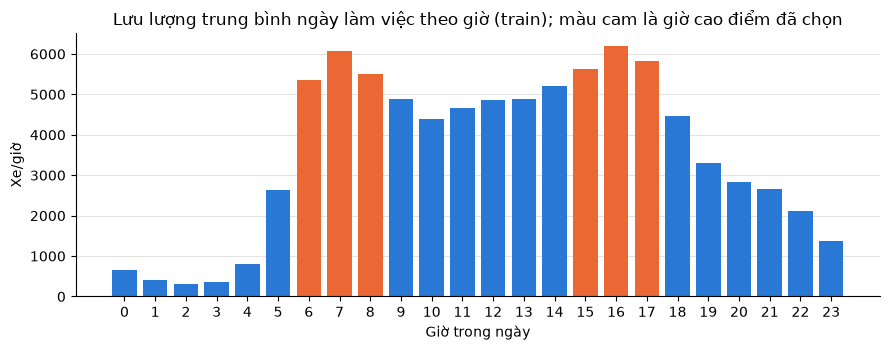

Giờ cao điểm: (6, 7, 8, 15, 16, 17)
Trung bình thấp nhất trong nhóm: 5363
Trung bình cao nhất ngoài nhóm: 5206


In [5]:
weekday_profile = train[train["is_weekend"].eq(0)].groupby("hour")["traffic_volume"].mean()

fig, ax = plt.subplots(figsize=(9, 3.6))
colors = [ORANGE if hour in RUSH_HOURS else BLUE for hour in weekday_profile.index]
ax.bar(weekday_profile.index, weekday_profile.to_numpy(), color=colors, width=0.8)
ax.set(title="Lưu lượng trung bình ngày làm việc theo giờ (train); màu cam là giờ cao điểm đã chọn",
       xlabel="Giờ trong ngày", ylabel="Xe/giờ", xticks=range(0, 24))
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print("Giờ cao điểm:", RUSH_HOURS)
print("Trung bình thấp nhất trong nhóm:", round(weekday_profile.loc[list(RUSH_HOURS)].min()))
print("Trung bình cao nhất ngoài nhóm:", round(weekday_profile.drop(list(RUSH_HOURS)).max()))

**Nhận xét**

- Hai đỉnh ngày làm việc của train nằm ở 06:00–08:00 và 15:00–17:00. Giờ thấp nhất trong nhóm cao điểm có trung bình 5.363 xe/giờ, cao hơn giờ cao nhất ngoài nhóm (14:00, 5.206 xe/giờ).
- Khoảng cách giữa hai mức chỉ khoảng 160 xe/giờ, nên ranh giới mang tính quy ước. Các mô hình cây vẫn nhận `hour`, nên `is_rush_hour` chủ yếu hỗ trợ cách biểu diễn, không thay thế giờ.

## 2.4 · Huấn luyện và tuning

Mọi cấu hình dùng cùng lưới tham số trong `src/models.py`, cùng số lượt thử và ba fold `TimeSeriesSplit` trong train. Ridge dùng one-hot cặp thứ–giờ vì mô hình tuyến tính không tự tạo tương tác; V_1 dùng one-hot riêng thứ và giờ. Cây dùng cột số và sin/cos.

In [6]:
results = []
for config, columns in [
    ("T0_thu_gio", V1_FEATURES),
    ("T1_lich", CALENDAR_FEATURES),
    ("A_lich_le", CONFIG_A),
]:
    results += run_config(config, columns, train, validation)

save_results("V_2", results, validation, output_dir)
table = results_table(results)

baseline_prediction = weekday_hour_baseline(train, validation)
baseline_metrics = regression_metrics(validation["traffic_volume"], baseline_prediction)
display(pd.concat([
    pd.DataFrame([{"config": "Trung bình thứ–giờ", "model": "Baseline", "so_dac_trung": 2, **baseline_metrics}]),
    table,
], ignore_index=True).sort_values("MAE").round(3))

,config,model,so_dac_trung,MAE,RMSE,R2,mean_cv_mae
9,A_lich_le,XGBoost,12,244.943,385.920,0.961,279.770
8,A_lich_le,Random Forest,12,248.705,396.713,0.959,282.805
5,T1_lich,Random Forest,11,276.832,474.251,0.942,294.416
6,T1_lich,XGBoost,11,278.895,475.555,0.941,298.706
7,A_lich_le,Ridge,12,283.098,453.231,0.947,313.146
3,T0_thu_gio,XGBoost,2,284.973,501.420,0.935,303.249
0,Trung bình thứ–giờ,Baseline,2,285.027,501.407,0.935,NaN
2,T0_thu_gio,Random Forest,2,285.113,501.423,0.935,303.242
1,T0_thu_gio,Ridge,2,285.134,501.371,0.935,303.523
4,T1_lich,Ridge,11,291.797,490.423,0.938,307.725


**Nhận xét**

- Với cùng thông tin thứ–giờ (`T0_thu_gio`), cả ba mô hình đạt MAE khoảng 285, gần như bằng baseline trung bình thứ–giờ (285,03). Khi chỉ có hai cột này, mô hình không học thêm được gì ngoài bảng trung bình.
- Ridge dùng one-hot cặp thứ–giờ đạt MAE 285,13, trong khi Ridge của V_1 dùng one-hot riêng thứ và giờ đạt 581,94. Chênh lệch của V_1 đến từ việc thiếu tương tác thứ–giờ, không phải do mô hình tuyến tính tự nó kém.
- `A_lich_le` cho kết quả tốt nhất: XGBoost MAE 244,94, RMSE 385,92, R² 0,961; Random Forest MAE 248,71. So với baseline thứ–giờ, XGBoost giảm khoảng 40 xe/giờ (14%).
- MAE CV trung bình (279,8 với XGBoost) cao hơn MAE validation. Các fold CV có đoạn chứa khoảng thiếu 7.386 giờ và giai đoạn khác validation, nên không so trực tiếp hai con số.
- Metrics tính trên validation; test chưa được dùng.

## 2.5 · Đối chứng từng bước

Chênh lệch dương nghĩa là cấu hình sau có MAE thấp hơn. Khoảng tin cậy 95% lấy mẫu lại theo ngày (bootstrap), vì các giờ trong cùng ngày không độc lập. Khoảng này chỉ mô tả độ dao động trên tập validation hiện tại.

In [7]:
by_key = {(item["config"], item["model"]): item for item in results}
rows = []
for before, after in [("T0_thu_gio", "T1_lich"), ("T1_lich", "A_lich_le")]:
    for model in ["Ridge", "Random Forest", "XGBoost"]:
        rows.append({
            "so_sanh": f"{before} → {after}", "model": model,
            **bootstrap_mae_difference(
                validation, by_key[(before, model)]["prediction"], by_key[(after, model)]["prediction"]
            ),
        })
display(pd.DataFrame(rows).round(2))

,so_sanh,model,chenh_lech_MAE,CI95_thap,CI95_cao,so_ngay
0,T0_thu_gio → T1_lich,Ridge,-6.66,-15.37,1.86,255
1,T0_thu_gio → T1_lich,Random Forest,8.28,-4.23,20.62,255
2,T0_thu_gio → T1_lich,XGBoost,6.08,-6.17,18.41,255
3,T1_lich → A_lich_le,Ridge,8.70,-4.10,19.38,255
4,T1_lich → A_lich_le,Random Forest,28.13,10.59,47.71,255
5,T1_lich → A_lich_le,XGBoost,33.95,15.64,55.43,255


**Nhận xét**

- Thêm đặc trưng lịch (`T0 → T1`) chưa có cải thiện rõ: Random Forest và XGBoost giảm 8,28 và 6,08 xe/giờ nhưng khoảng tin cậy đều chứa 0; Ridge tăng 6,66.
- Thêm `is_holiday` (`T1 → A`) cải thiện rõ với mô hình cây: XGBoost giảm 33,95 xe/giờ (CI 95%: 15,64–55,43), Random Forest giảm 28,13 (10,59–47,71). Với Ridge, mức giảm 8,70 chưa đủ rõ (−4,10 đến 19,38).
- Khoảng tin cậy chỉ phản ánh dao động theo ngày trên validation. Chưa phản ánh dao động do seed hoặc do chọn tham số.

## 2.6 · Sai số ở giờ ngày lễ và giờ thường

So sánh `T1_lich` và `A_lich_le` của XGBoost trên cùng các giờ, kèm số mẫu.

In [8]:
group = np.where(validation["is_holiday"].eq(1), "Ngày có nhãn lễ", "Ngày không có nhãn")
holiday_table = errors_by_group(validation, group, by_key[("T1_lich", "XGBoost")]["prediction"], "nhom").join(
    errors_by_group(validation, group, by_key[("A_lich_le", "XGBoost")]["prediction"], "nhom")[["MAE", "sai_so_tb"]],
    rsuffix="_co_is_holiday",
)
display(holiday_table.round(1))

event_days = validation[validation["is_holiday"].eq(1)]
per_event = errors_by_group(
    event_days, event_days["holiday_name"],
    by_key[("A_lich_le", "XGBoost")]["prediction"][validation["is_holiday"].eq(1).to_numpy()], "su_kien",
).sort_values("MAE", ascending=False)
display(per_event.round(1))

,so_gio,luu_luong_tb,MAE,sai_so_tb,MAE_co_is_holiday,sai_so_tb_co_is_holiday
nhom,,,,,,
Ngày có nhãn lễ,240,2618.1,925.6,706.9,474.8,-39.4
Ngày không có nhãn,5846,3391.1,252.3,-113.8,235.5,-86.2


,so_gio,luu_luong_tb,MAE,sai_so_tb
su_kien,,,,
Veterans Day,24,3706.9,993.8,-946.2
New Years Day,24,1749.3,912.4,717.7
Christmas Day,24,1889.8,560.9,326.0
Thanksgiving Day,24,2053.0,482.4,222.9
State Fair,24,3892.4,461.8,-335.2
Labor Day,24,2395.2,347.3,126.4
Columbus Day,24,3496.6,279.7,-204.9
Martin Luther King Jr Day,24,2677.2,252.6,-210.2
Independence Day,24,2133.5,243.1,-117.1


**Nhận xét**

- Trên 240 giờ có nhãn lễ, XGBoost không có `is_holiday` có MAE 925,6 và dự đoán cao hơn thực tế trung bình 706,9 xe/giờ. Khi thêm `is_holiday`, MAE còn 474,8 và sai số trung bình còn −39,4.
- Các giờ thường cũng giảm MAE từ 252,3 xuống 235,5, vì mô hình không còn phải trộn ngày lễ vào mức trung bình của ngày thường.
- Một cờ chung chưa đủ cho mọi sự kiện. Veterans Day (10/11/2017, thứ Sáu nghỉ bù) có MAE 993,8 và bị dự đoán **thấp** 946,2 xe/giờ, vì lưu lượng ngày này gần như ngày làm việc. Ngược lại, New Years Day bị dự đoán cao 717,7 xe/giờ.
- Mỗi sự kiện chỉ có 24 giờ của một ngày trong validation, nên chưa đủ để kết luận về từng loại lễ.

## 2.7 · Độ nhạy khi bổ sung các ngày lễ bị thiếu nhãn

Phương án đề xuất, chưa thay đổi quy tắc chính: `complete_holidays=True` thêm các ngày lễ liên bang thiếu nhãn. Các ngày này đều nằm trong train nên nhãn validation không đổi. Giữ nguyên tham số đã chọn của XGBoost.

In [9]:
features_completed = build_features(load_splits(complete_holidays=True))
assert features_completed["validation"]["is_holiday"].equals(validation["is_holiday"])
print("Số giờ train đổi nhãn:", int(features_completed["train"]["is_holiday"].sum() - train["is_holiday"].sum()))

best_params = by_key[("A_lich_le", "XGBoost")]["search"].best_params_
completed_model = make_model("XGBoost", CONFIG_A).set_params(**best_params)
completed_model.fit(features_completed["train"][CONFIG_A], features_completed["train"]["traffic_volume"])
completed_prediction = completed_model.predict(validation[CONFIG_A])

display(pd.DataFrame({
    "Nhãn theo CSV": by_key[("A_lich_le", "XGBoost")]["metrics"],
    "Bổ sung theo lịch": regression_metrics(validation["traffic_volume"], completed_prediction),
}).T.round(3))
print(bootstrap_mae_difference(validation, by_key[("A_lich_le", "XGBoost")]["prediction"], completed_prediction))

Số giờ train đổi nhãn: 54


,MAE,RMSE,R2
Nhãn theo CSV,244.943,385.92,0.961
Bổ sung theo lịch,244.358,386.37,0.961


{'chenh_lech_MAE': 0.5844844551098962, 'CI95_thap': -0.9327863984851414, 'CI95_cao': 2.118514258541599, 'so_ngay': 255}


**Nhận xét**

- Bổ sung nhãn đổi 54 giờ trong train. MAE validation giảm từ 244,94 xuống 244,36 (CI 95%: −0,93 đến 2,12): chưa thấy khác biệt rõ.
- Phương án bổ sung đúng hơn về mặt dữ liệu, nhưng kết quả hiện tại chưa cho thấy lợi ích dự đoán. Nhóm cần thống nhất có đổi quy tắc trong `preprocessing_features.ipynb` hay không.

## 2.8 · Ghi nhật ký thực nghiệm

In [10]:
# Log chỉ được tạo khi chủ động bật; đặt biến môi trường SAVE_EXPERIMENT_LOGS=1
# hoặc đổi giá trị bên dưới thành True. Mỗi lần ghi tạo file mới, không ghi đè.
SAVE_EXPERIMENT_LOGS = os.environ.get("SAVE_EXPERIMENT_LOGS") == "1"

common_observations = run_observations(data_path, splits, "notebooks/experiments/V_2.ipynb")
common_problems = ['Dữ liệu thiếu giờ; validation chỉ gồm các giờ quan sát được.', 'Validation chỉ có 10 ngày có nhãn sự kiện; kết quả theo từng sự kiện có ít mẫu.']
next_steps = ['So sánh Time với Time + Weather trong V_3.']

if SAVE_EXPERIMENT_LOGS:
    for item in results:
        log_path = save_experiment_log(
            model=f"{item['config']} - {item['model']}",
            features=item["features"],
            results=item["metrics"],
            observations=common_observations + [
                "Tập đánh giá: " + item.get("tap_danh_gia", f"validation; {len(validation)} giờ."),
                f"Tham số được chọn: {item['search'].best_params_}",
                f"MAE trung bình CV: {-item['search'].best_score_}",
                f"Kết quả từng fold: {summarize_search(item['search']).to_json(orient='records', force_ascii=False)}",
            ],
            problems=common_problems,
            next_steps=next_steps,
        )
        print("Đã lưu:", log_path.name)
else:
    print("Chưa tạo log. Đặt SAVE_EXPERIMENT_LOGS=1 khi cần ghi.")

Đã lưu: EXP_007.txt
Đã lưu: EXP_008.txt


Đã lưu: EXP_009.txt
Đã lưu: EXP_010.txt
Đã lưu: EXP_011.txt
Đã lưu: EXP_012.txt
Đã lưu: EXP_013.txt
Đã lưu: EXP_014.txt
Đã lưu: EXP_015.txt


### Kết luận V_2

| Cấu hình | XGBoost MAE | Random Forest MAE | Ridge MAE |
|---|---|---|---|
| T0_thu_gio | 284,97 | 285,11 | 285,13 |
| T1_lich | 278,90 | 276,83 | 291,80 |
| A_lich_le | **244,94** | 248,71 | 283,10 |

- Đặc trưng ngày lễ đóng góp rõ nhất trong nhóm đặc trưng thời gian. Đặc trưng lịch (tháng, sin/cos, cao điểm) chưa cải thiện rõ trên validation.
- Cấu hình A được dùng làm mốc cho V_3. Dự đoán, metrics và tham số được lưu trong `outputs/`.
- Còn mở: phân biệt loại lễ, ngày nghỉ bù và các ngày sát lễ; quyết định có bổ sung nhãn lễ thiếu hay không.